# Тасалбарын төлбөр × Амьд үлдэлт — Split Violin Plot

**Зорилго:** тасалбарын үнэ амьд үлдэлттэй хэрхэн холбоотой болохыг зэрэг тус бүрт **нарийвчлан** харуулах.

**Яагаад split violin?**
- Нэг violin-ийн **зүүн хагас = нас барсан**, **баруун хагас = амьд үлдсэн** → хоёр тархалтыг нэг тэнхлэг дээр шууд харьцуулна (preattentive: байрлал + өнгө).
- Хайрцган графикаас (boxplot) ялгаатай нь тархалтын **хэлбэр** (олон оргил, сүүл) харагдана.
- `density_norm='count'` → хагасын өргөн = хүний тоо, тиймээс 3-р зэрэгт нас барсан хүмүүс олон байсныг талбайгаар мэдэрнэ.

**Хоёр самбар:** ① `Fare` (нэг тасалбарын нийт үнэ) ба ② нэг хүнд ногдох үнэ (`Fare` ÷ тасалбарын хүний тоо).

> Шаардлага: `seaborn >= 0.13` (`pip install -U seaborn`), `titanic.csv` notebook-той нэг хавтаст.

## 1. Сан, өгөгдөл, өнгө

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ── 1. Өгөгдөл ──────────────────────────────────────────────
df = pd.read_csv('titanic.csv')
df = df[df['Fare'] > 0].copy()                                    # 15 үнэгүй тасалбар → лог масштабд 0 болохгүй
df['Тасалбар_бүлэг'] = df.groupby('Ticket')['Ticket'].transform('size')
df['Хүнд_ногдох'] = df['Fare'] / df['Тасалбар_бүлэг']
df['Зэрэг'] = df['Pclass'].map({1: '1-р зэрэг', 2: '2-р зэрэг', 3: '3-р зэрэг'})
df['Төлөв'] = df['Survived'].map({0: 'Нас барсан', 1: 'Амьд үлдсэн'})

ORDER = ['1-р зэрэг', '2-р зэрэг', '3-р зэрэг']
HUE_ORDER = ['Нас барсан', 'Амьд үлдсэн']
PALETTE = {'Нас барсан': '#c3c2b7', 'Амьд үлдсэн': '#2a78d6'}   # саарал vs цэнхэр — өнгөний харалган хүнд ч ялгагдана
INK, INK2, MUTED, SURFACE = '#0b0b0b', '#52514e', '#898781', '#fcfcfb'

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11, 'figure.dpi': 110,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
})

## 2. Split violin зурах функц
Нэг самбар дээр: violin (тархалт) + цэг (хүн бүр) + хар зураас (25–75%) + ○ (медиан). Медиан, зөрүү, n-ийг x тэнхлэгийн шошгонд бичнэ; зөрүү ±15%-иас их бол тод харагдана.

In [2]:
def split_violin(ax, col, title, subtitle):
    """col баганын тархалтыг зэрэг × амьд үлдэлтээр split violin-оор зурна (лог10 масштаб)."""
    d = df.assign(_y=np.log10(df[col]))

    # ── Split violin ──
    sns.violinplot(
        data=d, x='Зэрэг', y='_y', hue='Төлөв', order=ORDER, hue_order=HUE_ORDER, palette=PALETTE,
        split=True,            # зүүн хагас = нас барсан, баруун хагас = амьд үлдсэн
        inner=None,            # дотоод зургийг доор гараар нарийвчлан зурна
        cut=0,                 # өгөгдлийн хүрээнээс гадуур сунгахгүй
        bw_adjust=0.6,         # нягтын нарийвчлал (бага = нарийн)
        density_norm='count',  # хагасын өргөн ∝ хүний тоо
        gap=0.06, linewidth=0, saturation=1, legend=False, ax=ax)

    rng = np.random.default_rng(0)
    xlabels, strong = [], []
    for i, cls in enumerate(ORDER):
        meds = {}
        for side, status in zip([-1, 1], HUE_ORDER):
            v = d[(d['Зэрэг'] == cls) & (d['Төлөв'] == status)]['_y']
            # (а) хүн бүр = жижиг цэг
            ax.scatter(i + side * rng.uniform(0.03, 0.10, len(v)), v, s=4, lw=0, alpha=0.35, zorder=3,
                       color=INK if status == 'Амьд үлдсэн' else MUTED)
            # (б) 25–75% квартиль
            q1, med, q3 = np.percentile(v, [25, 50, 75])
            ax.plot([i + side * 0.015] * 2, [q1, q3], color=INK, lw=4, solid_capstyle='butt', zorder=4)
            # (в) медиан
            ax.scatter(i + side * 0.015, med, s=34, color='white', edgecolor=INK, linewidth=1.3, zorder=5)
            meds[status] = 10 ** med
        # (г) медиан, зөрүү, n → x тэнхлэгийн шошгонд
        diff = round(meds['Амьд үлдсэн'] / meds['Нас барсан'] - 1, 2) + 0.0
        n_d = ((d['Зэрэг'] == cls) & (d['Survived'] == 0)).sum()
        n_s = ((d['Зэрэг'] == cls) & (d['Survived'] == 1)).sum()
        xlabels.append(f"{cls}\n£{meds['Нас барсан']:.1f}  vs  £{meds['Амьд үлдсэн']:.1f}  ({diff:+.0%})\nn = {n_d} | {n_s}")
        strong.append(abs(diff) >= 0.15)

    ax.set_xticks(range(3), xlabels)
    for lab, st in zip(ax.get_xticklabels(), strong):
        lab.set_color(INK if st else MUTED); lab.set_fontweight('bold' if st else 'normal'); lab.set_fontsize(10)
    ticks = [3, 5, 10, 20, 50, 100, 200, 500]
    ax.set_yticks(np.log10(ticks), [f'£{t}' for t in ticks])
    ax.set_ylim(np.log10(2.5), np.log10(560))
    ax.set_xlim(-0.6, 2.6); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', pad=6, length=0)
    ax.set_title(title, loc='left', fontsize=12.5, fontweight='bold', color=INK, pad=26)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.5, color=INK2)

## 3. График: нийт үнэ vs хүнд ногдох үнэ

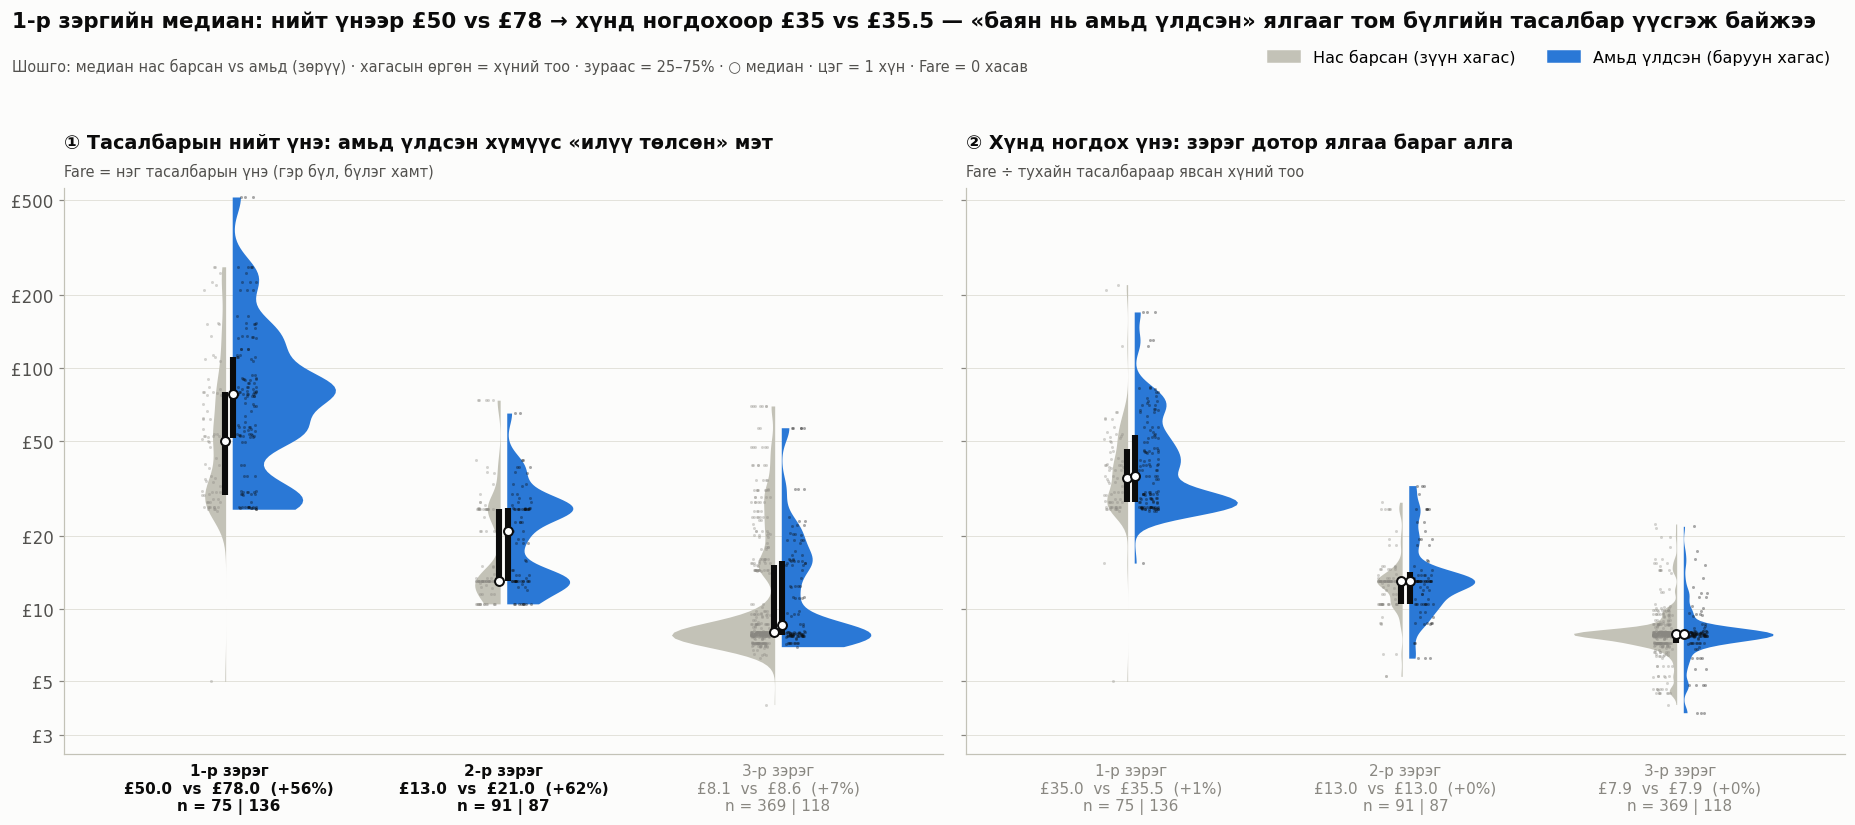

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 7.4), sharey=True)
split_violin(a1, 'Fare', '① Тасалбарын нийт үнэ: амьд үлдсэн хүмүүс «илүү төлсөн» мэт',
             'Fare = нэг тасалбарын үнэ (гэр бүл, бүлэг хамт)')
split_violin(a2, 'Хүнд_ногдох', '② Хүнд ногдох үнэ: зэрэг дотор ялгаа бараг алга',
             'Fare ÷ тухайн тасалбараар явсан хүний тоо')
fig.legend(handles=[Patch(color=PALETTE[k], label=f'{k} ({"зүүн" if k == "Нас барсан" else "баруун"} хагас)') for k in HUE_ORDER],
           loc='upper right', ncol=2, frameon=False, fontsize=10.5, bbox_to_anchor=(0.99, 1.0))
fig.suptitle('1-р зэргийн медиан: нийт үнээр £50 vs £78 → хүнд ногдохоор £35 vs £35.5 — '
             '«баян нь амьд үлдсэн» ялгааг том бүлгийн тасалбар үүсгэж байжээ',
             x=0.01, ha='left', fontsize=14, fontweight='bold', color=INK, y=1.03)
fig.text(0.01, 0.955, 'Шошго: медиан нас барсан vs амьд (зөрүү) · хагасын өргөн = хүний тоо · зураас = 25–75% · ○ медиан · цэг = 1 хүн · Fare = 0 хасав',
         fontsize=9.5, color=INK2)
plt.tight_layout(rect=(0, 0.02, 1, 0.95))
plt.savefig('split_violin_fare.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Тоон хураангуй

In [4]:
# ── Тоон хураангуй ─────────────────────────────────────────
tbl = df.groupby(['Зэрэг', 'Төлөв']).agg(n=('Fare', 'size'),
                                          Fare_медиан=('Fare', 'median'),
                                          Хүнд_ногдох_медиан=('Хүнд_ногдох', 'median'),
                                          Тасалбарын_бүлэг_дундаж=('Тасалбар_бүлэг', 'mean')).round(2)
print(tbl)
display(tbl)

                         n  Fare_медиан  Хүнд_ногдох_медиан  \
Зэрэг     Төлөв                                               
1-р зэрэг Амьд үлдсэн  136        77.96               35.50   
          Нас барсан    75        50.00               35.00   
2-р зэрэг Амьд үлдсэн   87        21.00               13.00   
          Нас барсан    91        13.00               13.00   
3-р зэрэг Амьд үлдсэн  118         8.59                7.85   
          Нас барсан   369         8.05                7.85   

                       Тасалбарын_бүлэг_дундаж  
Зэрэг     Төлөв                                 
1-р зэрэг Амьд үлдсэн                     2.04  
          Нас барсан                      1.60  
2-р зэрэг Амьд үлдсэн                     1.66  
          Нас барсан                      1.58  
3-р зэрэг Амьд үлдсэн                     1.77  
          Нас барсан                      1.80  


n  Fare_медиан  Хүнд_ногдох_медиан  \
Зэрэг     Төлөв                                               
1-р зэрэг Амьд үлдсэн  136        77.96               35.50   
          Нас барсан    75        50.00               35.00   
2-р зэрэг Амьд үлдсэн   87        21.00               13.00   
          Нас барсан    91        13.00               13.00   
3-р зэрэг Амьд үлдсэн  118         8.59                7.85   
          Нас барсан   369         8.05                7.85   

                       Тасалбарын_бүлэг_дундаж  
Зэрэг     Төлөв                                 
1-р зэрэг Амьд үлдсэн                     2.04  
          Нас барсан                      1.60  
2-р зэрэг Амьд үлдсэн                     1.66  
          Нас барсан                      1.58  
3-р зэрэг Амьд үлдсэн                     1.77  
          Нас барсан                      1.80

## 5. Тайлбар

| Самбар | 1-р зэрэг: нас барсан vs амьд үлдсэн | Утга |
|---|---|---|
| ① Нийт үнэ (`Fare`) | £50 vs £78 (**+56%**) | Амьд үлдсэн хүмүүс «илүү төлсөн» мэт |
| ② Хүнд ногдох үнэ | £35 vs £35.5 (**+1%**) | Зэрэг дотор ялгаа бараг алга |

**Шалтгаан:** `Fare` нь нэг тасалбараар хамт явсан бүлгийн **нийт** үнэ. 1-р зэрэгт амьд үлдсэн хүмүүс дунджаар 2.04 хүнтэй, нас барсан хүмүүс 1.60 хүнтэй тасалбартай байсан → олон хүнтэй тасалбар нийт үнийг өсгөсөн.

**Дүгнэлт:** Зэрэг доторх ялгааг үнэ биш, **хэнтэй хамт явсан** нь тайлбарлаж байна. Үнийн нөлөө нь зөвхөн **зэргээр дамжиж** гарна (1-р £35 → 3-р £8).

**Visual mapping сургамж:** талбарын **нэгжийг** (хүн үү, тасалбар уу) шалгахгүй бол хамгийн «нарийн» график ч хуурамч дүгнэлт гаргана.